# Activities

We analyse three types of GitHub activity in the kubernetes/kubernetes repository for calendar year 2025: commits, pull requests (PRs) opened, and issues opened. In total, the repository saw 7141 commits, 4569 PRs and 1859 issues in this period.

The figure below shows the monthly count of each activity. Commits are the most frequent activity throughout the year, followed by pull requests, while issues are the least frequent and remain stable at roughly 200 per month. Code-related activity (commits and PRs) is therefore far larger and more variable than issue reporting, so the balance leans heavily toward development work rather than problem reporting.

The most notable feature is three pronounced peaks in commits, spaced roughly four months apart, in March, July and October. PRs peak in the same months. This matches Kubernetes' release cadence of about three minor releases per year. Activity likely rises as contributors merge work ahead of the release. The parallel PR peaks are expected because most commits in the repository are merge commits created when a PR is merged, so the two counts are partly linked by construction. The stable issue count suggests that bug reporting is independent of the release cycle.

In [ ]:
from octokit import Octokit
import time, calendar
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
# constants

k8_url = "https://github.com/kubernetes/kubernetes"
token =""
owner = repo = "kubernetes"

In [4]:
#create client, get repository

client = Octokit(auth = "token", token = token)
repo = client.repos.get(owner= owner, repo= repo)

In [5]:
print(repo.json)

{'id': 20580498, 'node_id': 'MDEwOlJlcG9zaXRvcnkyMDU4MDQ5OA==', 'name': 'kubernetes', 'full_name': 'kubernetes/kubernetes', 'private': False, 'owner': {'login': 'kubernetes', 'id': 13629408, 'node_id': 'MDEyOk9yZ2FuaXphdGlvbjEzNjI5NDA4', 'avatar_url': 'https://avatars.githubusercontent.com/u/13629408?v=4', 'gravatar_id': '', 'url': 'https://api.github.com/users/kubernetes', 'html_url': 'https://github.com/kubernetes', 'followers_url': 'https://api.github.com/users/kubernetes/followers', 'following_url': 'https://api.github.com/users/kubernetes/following{/other_user}', 'gists_url': 'https://api.github.com/users/kubernetes/gists{/gist_id}', 'starred_url': 'https://api.github.com/users/kubernetes/starred{/owner}{/repo}', 'subscriptions_url': 'https://api.github.com/users/kubernetes/subscriptions', 'organizations_url': 'https://api.github.com/users/kubernetes/orgs', 'repos_url': 'https://api.github.com/users/kubernetes/repos', 'events_url': 'https://api.github.com/users/kubernetes/events{/

In [6]:
# methods this version has
print([m for m in dir(client.search) if not m.startswith("_")])

['code', 'commits', 'issues', 'issues_and_pull_requests', 'labels', 'repos', 'search_code', 'search_commits', 'search_issues_and_pull_requests', 'search_labels', 'search_repositories', 'search_topics', 'search_users', 'topics', 'users']


In [7]:
REPO = "repo:kubernetes/kubernetes"
rng = "2025-01-01..2025-12-31"

def count(method, q):
    return getattr(client.search, method)(q=q, per_page=1).json["total_count"]

print("issues :", count("issues_and_pull_requests", f"{REPO} is:issue created:{rng}"))
print("prs    :", count("issues_and_pull_requests", f"{REPO} is:pr created:{rng}"))
print("commits:", count("commits", f"{REPO} committer-date:{rng}"))

issues : 1859
prs    : 4569
commits: 7141


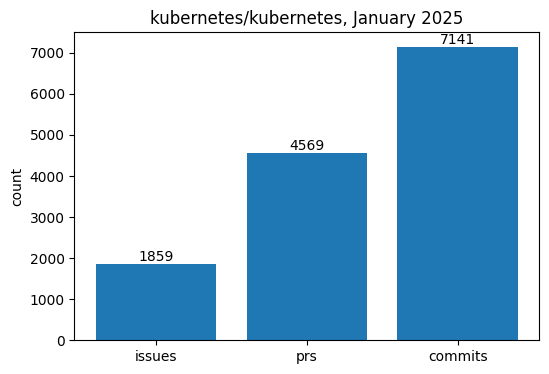

In [8]:
counts = {
    "issues":  count("issues_and_pull_requests", f"{REPO} is:issue created:{rng}"),
    "prs":     count("issues_and_pull_requests", f"{REPO} is:pr created:{rng}"),
    "commits": count("commits", f"{REPO} committer-date:{rng}"),
}

plt.figure(figsize=(6, 4))
bars = plt.bar(counts.keys(), counts.values())
plt.bar_label(bars)                      # prints the number on top of each bar
plt.ylabel("count")
plt.title("kubernetes/kubernetes, January 2025")
plt.show()

In [9]:
import time, calendar
import pandas as pd

REPO = "repo:kubernetes/kubernetes"

def count(method, q, tries=5):
    for _ in range(tries):
        j = getattr(client.search, method)(q=q, per_page=1).json
        time.sleep(3)
        if "total_count" in j:
            return j["total_count"]
        print("GitHub said:", j.get("message"), "- waiting 60s")
        time.sleep(60)
    raise RuntimeError(f"gave up on: {q}")

rows = []
for m in range(1, 13):
    last = calendar.monthrange(2025, m)[1]
    rng = f"2025-{m:02d}-01..2025-{m:02d}-{last}"
    rows.append({
        "month":   f"2025-{m:02d}",
        "commits": count("commits", f"{REPO} committer-date:{rng}"),
        "prs":     count("issues_and_pull_requests", f"{REPO} is:pr created:{rng}"),
        "issues":  count("issues_and_pull_requests", f"{REPO} is:issue created:{rng}"),
    })
    print("done", m)

df = pd.DataFrame(rows).set_index("month")
df.to_csv("k8s_activity_2025.csv")
df

done 1
done 2
done 3
done 4
done 5
done 6
done 7
done 8
done 9
done 10
done 11
done 12


,commits,prs,issues
month,,,
2025-01,446,324,163
2025-02,535,401,151
2025-03,958,417,194
2025-04,315,290,147
2025-05,544,333,140
2025-06,561,407,177
2025-07,1069,519,181
2025-08,368,282,153
2025-09,611,393,135


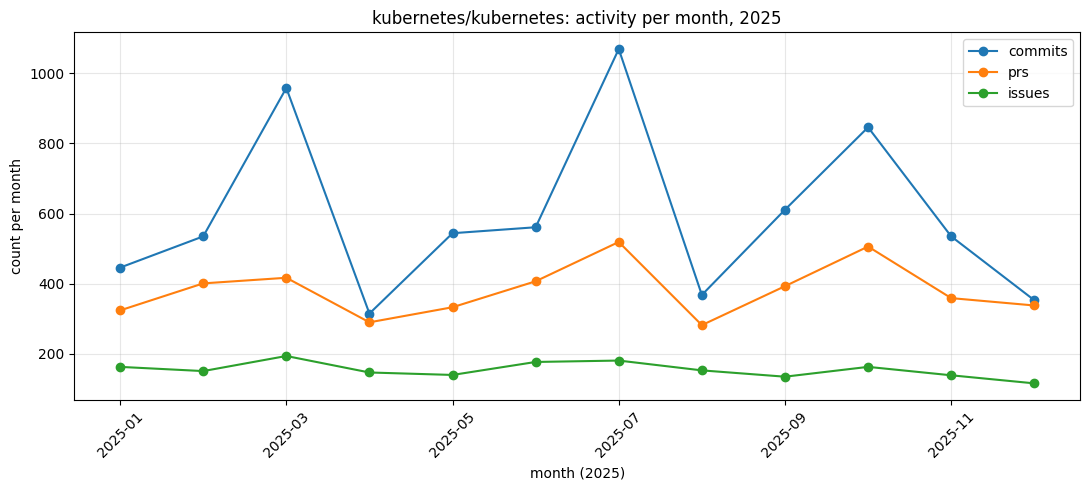

commits    7141
prs        4569
issues     1859
dtype: int64


In [10]:
import matplotlib.pyplot as plt

ax = df.plot(kind="line", marker="o", figsize=(11, 5))
ax.set_ylabel("count per month")
ax.set_xlabel("month (2025)")
ax.set_title("kubernetes/kubernetes: activity per month, 2025")
ax.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(df.sum())   # yearly totals

In [ ]:
import time

# pick whichever contributors method this octokitpy version has
name = next((n for n in ("list_contributors", "get_contributors") if hasattr(client.repos, n)), None)
print("using:", name)

if name is None:
    print([m for m in dir(client.repos) if "contrib" in m or "stat" in m])
else:
    fetch = getattr(client.repos, name)
    total, page = 0, 1
    while True:
        batch = fetch(owner="kubernetes", repo="kubernetes",
                      per_page=100, page=page, anon="false").json
        if not isinstance(batch, list) or not batch:
            print("stopped at page", page, "->", batch if not isinstance(batch, list) else "empty")
            break
        total += len(batch)
        page += 1
        time.sleep(0.5)
    print("total contributors (all time, incl. anonymous):", total)

using: list_contributors
stopped at page 61 -> empty
total contributors (all time, incl. anonymous): 5908
